# Eau et activités économiques en Bretagne

**Quels territoires sont les plus exposés à la sécheresse ?**

Ce notebook analyse les tables produites par le pipeline (`python -m eau_bretagne tout`).
Il croise les prélèvements déclarés (Hub'Eau, 2008-2024), les restrictions préfectorales par
commune (VigiEau, 2012 au 15 septembre 2026), les niveaux de nappes (Hub'Eau) et le répertoire
Sirene.

**Ce que ces données ne disent pas.** Hub'Eau ne compte que l'eau prélevée directement dans le
milieu. L'eau achetée au réseau public, celle de la plupart des PME, y est comptée en « eau
potable », sans distinction d'utilisateur. C'est pourquoi l'analyse porte sur l'exposition des
territoires, qui concerne toutes les entreprises, et non sur la consommation de chaque PME.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from eau_bretagne import transform as t

P = "../data/processed/"
communes = pd.read_parquet(P + "dim_commune.parquet")
prelevements = pd.read_parquet(P + "fact_prelevements.parquet")
restrictions = pd.read_parquet(P + "fact_restrictions_mois.parquet")
tailles = pd.read_parquet(P + "fact_taille.parquet")
nappes = pd.read_parquet(P + "fact_nappes_mois.parquet")
economiques = pd.read_parquet(P + "prelevements_economiques.parquet")

BLEU, ORANGE, ENCRE, GRIS, GRILLE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 130, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.edgecolor": GRILLE, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRILLE, "axes.axisbelow": True, "axes.labelcolor": GRIS,
    "xtick.color": GRIS, "ytick.color": GRIS, "xtick.bottom": False, "ytick.left": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
})


def enregistrer(nom):
    plt.tight_layout()
    plt.savefig(f"../docs/figures/{nom}.png", bbox_inches="tight")
    plt.show()

## 1. La pression : l'eau potable domine, l'eau économique recule

En 2024, 276 millions de m³ ont été prélevés hors barrages. L'eau potable en représente 91 %,
les activités économiques 8 % et l'irrigation 2 %. Près des trois quarts proviennent des eaux
de surface : c'est la fragilité bretonne, car cours d'eau et retenues réagissent vite à un
manque de pluie.

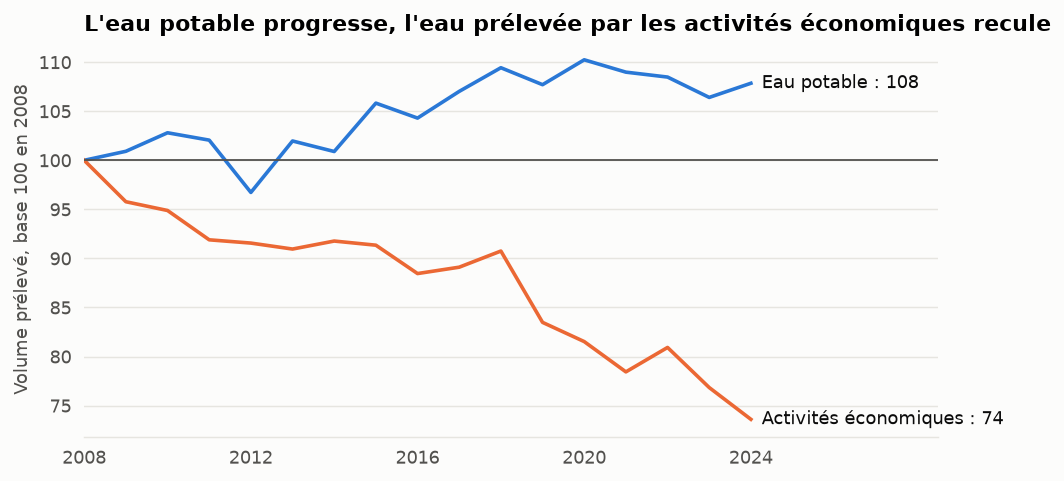

usage,Activités économiques,Eau potable,Irrigation
annee,,,
2008,29.0,232.2,6.5
2015,26.4,245.8,8.8
2022,23.4,251.9,9.1
2024,21.3,250.5,4.6


In [2]:
volumes = prelevements.pivot_table(index="annee", columns="usage", values="volume_m3", aggfunc="sum")
indice = volumes[["Eau potable", "Activités économiques"]].div(volumes.loc[2008, ["Eau potable", "Activités économiques"]]) * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
for usage, couleur in [("Eau potable", BLEU), ("Activités économiques", ORANGE)]:
    ax.plot(indice.index, indice[usage], color=couleur, lw=2)
    ax.annotate(f"{usage} : {indice[usage].iloc[-1]:.0f}", (2024, indice[usage].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", color=ENCRE)
ax.axhline(100, color=GRIS, lw=1)
ax.set_title("L'eau potable progresse, l'eau prélevée par les activités économiques recule")
ax.set_ylabel("Volume prélevé, base 100 en 2008")
ax.set_xlim(2008, 2028.5); ax.set_xticks(range(2008, 2025, 4))
enregistrer("1_prelevements_base100")
(volumes / 1e6).round(1).loc[[2008, 2015, 2022, 2024]]

## 2. Qui prélève directement ? Surtout l'agroalimentaire et les grands groupes

L'agroalimentaire pèse 59 % de l'eau économique en 2024. Le rapprochement avec Sirene montre
aussi que les PME identifiées ne représentent qu'environ 8 % de ce volume. Ce résultat confirme
le point de départ : la plupart des PME ne prélèvent pas directement.

Le rapprochement n'est pas parfait. Le secteur reste « non identifié » pour 32 ouvrages sur 255
et la taille n'est pas classée pour environ 9 % du volume de 2024.

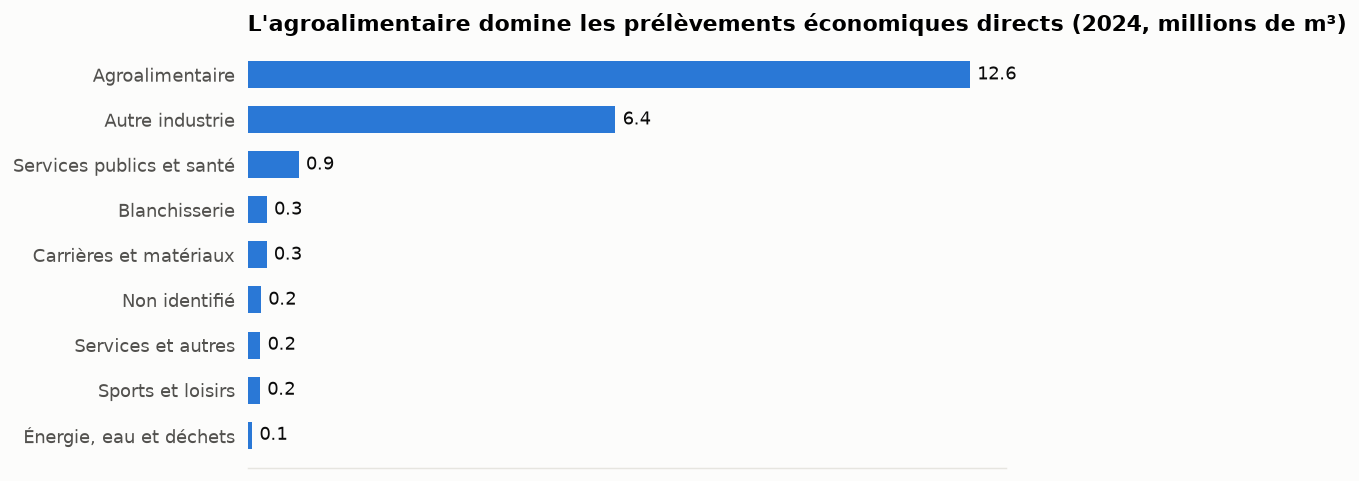

,part du volume 2024 (%),nb_ouvrages
taille,,
ETI,37.9,40
GE,44.6,48
Non classé,9.3,28
PME,8.2,25


In [3]:
derniere = economiques[economiques.annee == 2024].groupby("secteur").volume.sum().sort_values() / 1e6
fig, ax = plt.subplots(figsize=(8, 3.8))
barres = ax.barh(derniere.index, derniere.values, color=BLEU, height=0.6)
ax.bar_label(barres, fmt="%.1f", padding=4, color=ENCRE)
ax.grid(False); ax.set_xticks([])
ax.set_title("L'agroalimentaire domine les prélèvements économiques directs (2024, millions de m³)")
enregistrer("2_secteurs_2024")
t24 = tailles[tailles.annee == 2024].set_index("taille")
(t24.volume_m3 / t24.volume_m3.sum() * 100).round(1).rename("part du volume 2024 (%)").to_frame().join(t24.nb_ouvrages)

## 3. L'énigme de 2022 : un total trompeur

Le total économique **monte** en 2022, année de crise, alors que les usines ont dû réduire leur
consommation. La hausse vient de 5 ouvrages aux codes consécutifs qui entrent dans la base en
2022 pour 1,8 million de m³, sans prédécesseur identifiable. Cela ressemble à un enregistrement
groupé de sites déjà en activité plutôt qu'à une hausse réelle, une hypothèse à confirmer auprès
de l'agence de l'eau. Il faut donc raisonner **à périmètre constant**. Si cette hypothèse est
juste, les volumes d'avant 2022 sont sous-estimés et la baisse de long terme aussi.

Les 130 ouvrages actifs chaque année de 2021 à 2023 baissent de 4 % en 2022, puis de 10 % sur
deux ans. Cette baisse se poursuit en 2023, comme si les économies de la crise avaient en partie
perduré. Elle ne suffit pas à prouver un lien de cause à effet.

In [4]:
par_ouvrage = economiques.pivot_table(index="code_ouvrage", columns="annee", values="volume", aggfunc="sum")
periode = [2021, 2022, 2023]
constant = par_ouvrage[periode].dropna()
constant = constant[(constant > 0).all(axis=1)]
hors = par_ouvrage.drop(constant.index)[periode]
pd.DataFrame({
    "périmètre constant (Mm³)": constant.sum() / 1e6,
    "autres ouvrages (Mm³)": hors.sum() / 1e6,
    "total (Mm³)": par_ouvrage[periode].sum() / 1e6,
}).round(2).assign(**{"évolution constante (%)": lambda d: ((d.iloc[:, 0] / d.iloc[0, 0] - 1) * 100).round(1)})

,périmètre constant (Mm³),autres ouvrages (Mm³),total (Mm³),évolution constante (%)
annee,,,,
2021,22.53,0.18,22.71,0.0
2022,21.55,1.88,23.43,-4.3
2023,20.31,1.93,22.25,-9.9


Sur le long terme, les 84 ouvrages actifs en 2008 comme en 2024 baissent d'un tiers. Les
données ne permettent pas de distinguer une vraie sobriété d'un basculement vers le réseau
public : il s'agit d'une baisse des **prélèvements directs**, pas forcément de la consommation.

In [5]:
longue = par_ouvrage[[2008, 2024]].dropna()
longue = longue[(longue > 0).all(axis=1)]
print(f"{len(longue)} ouvrages : {longue[2008].sum()/1e6:.1f} -> {longue[2024].sum()/1e6:.1f} Mm³, "
      f"soit {(longue[2024].sum()/longue[2008].sum()-1)*100:.0f} %")

84 ouvrages : 26.4 -> 17.5 Mm³, soit -34 %


## 4. La sécheresse : compter les jours ne suffit pas

Trois profils ressortent. **2017** est longue mais modérée : 207 jours d'alerte en moyenne par
commune, aucun jour de crise. **2022** est plus courte et bien plus grave, avec 72 jours de crise
en moyenne. **2026** compte déjà 39 jours de crise, alors que les données s'arrêtent au
15 septembre : c'est la deuxième année de la série sur ce critère. Compter les jours mettrait
2017 en tête, d'où le choix de les pondérer par la gravité dans l'indice.

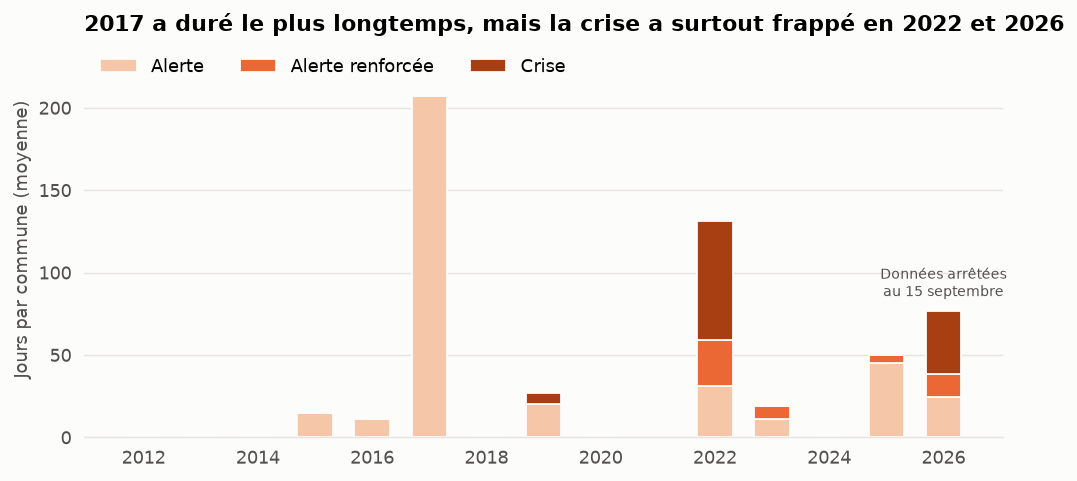

,jours_alerte,jours_alerte_renforcee,jours_crise
mois,,,
2017,206.9,0.0,0.0
2019,20.1,0.0,6.9
2022,31.0,28.3,72.2
2023,11.4,7.7,0.0
2025,44.8,4.9,0.6
2026,24.2,14.2,38.6


In [6]:
annees = range(2012, 2027)
gravite = restrictions.groupby(restrictions.mois.dt.year)[["jours_alerte", "jours_alerte_renforcee", "jours_crise"]].sum()
gravite = (gravite / len(communes)).reindex(annees, fill_value=0)

niveaux = [("jours_alerte", "Alerte", "#f5c6a8"), ("jours_alerte_renforcee", "Alerte renforcée", "#eb6834"), ("jours_crise", "Crise", "#a83f12")]
fig, ax = plt.subplots(figsize=(8, 3.8))
base = pd.Series(0.0, index=gravite.index)
for colonne, libelle, couleur in niveaux:
    ax.bar(gravite.index, gravite[colonne], bottom=base, color=couleur, label=libelle, width=0.62,
           edgecolor="#fcfcfb", linewidth=1)
    base += gravite[colonne]
ax.legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, 1.0))
ax.annotate("Données arrêtées\nau 15 septembre", (2026, base[2026]), xytext=(0, 8), textcoords="offset points", ha="center", color=GRIS, fontsize=8)
ax.set_xticks(list(annees)[::2])
ax.set_ylabel("Jours par commune (moyenne)")
ax.set_ylim(0, 240)
ax.set_title("2017 a duré le plus longtemps, mais la crise a surtout frappé en 2022 et 2026")
enregistrer("3_jours_restriction")
gravite.round(1).loc[[2017, 2019, 2022, 2023, 2025, 2026]]

## 5. Les restrictions suivent-elles l'état des nappes ?

Pour chaque département et chaque mois de juin à octobre, on compare le niveau des nappes,
situé par rapport au même mois des autres années, aux jours de restriction. La relation existe
(corrélation de Spearman de −0,57) sans être mécanique : à niveau égal, les décisions varient
d'un département à l'autre et d'une année à l'autre.

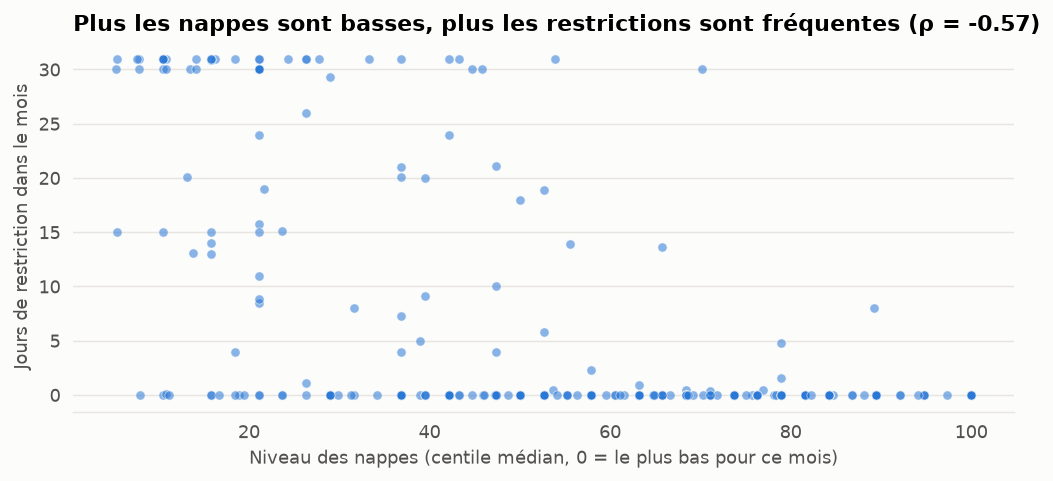

300 mois-départements, rho de Spearman = -0.57


In [7]:
par_dep = restrictions.merge(communes[["code_commune", "code_departement"]], on="code_commune")
par_dep = par_dep.groupby(["code_departement", "mois"], as_index=False).jours_restriction.sum()
par_dep["jours"] = par_dep.jours_restriction / par_dep.code_departement.map(communes.groupby("code_departement").size())
ete = nappes[nappes.mois >= "2012-01-01"].merge(par_dep, on=["code_departement", "mois"], how="left").fillna({"jours": 0})
ete = ete[ete.mois.dt.month.between(6, 10)]
rho = ete[["percentile_median", "jours"]].corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(ete.percentile_median, ete.jours, s=26, color=BLEU, alpha=0.55, edgecolor="#fcfcfb", linewidth=0.5)
ax.set_xlabel("Niveau des nappes (centile médian, 0 = le plus bas pour ce mois)")
ax.set_ylabel("Jours de restriction dans le mois")
ax.set_title(f"Plus les nappes sont basses, plus les restrictions sont fréquentes (ρ = {rho:.2f})")
enregistrer("4_nappes_restrictions")
print(f"{len(ete)} mois-départements, rho de Spearman = {rho:.2f}")

## 6. L'indice d'exposition

L'indice classe les 1 202 communes bretonnes les unes par rapport aux autres. Il combine trois
composantes converties en rangs :

| Composante | Poids | Mesure | Maille |
|---|---|---|---|
| Gravité des restrictions | 50 % | jours pondérés par an, 2016-2025 (alerte 1, renforcée 2, crise 3) | commune |
| Pression sur la ressource | 30 % | m³ prélevés par km², 2020-2024 | EPCI |
| Dépendance aux eaux de surface | 20 % | part du volume prélevé en surface, 2020-2024 | EPCI |

Ces poids sont un **choix d'analyste**, pas une vérité. Ils sont testés ci-dessous. L'indice est
relatif : une commune en classe « faible » peut très bien subir des restrictions.

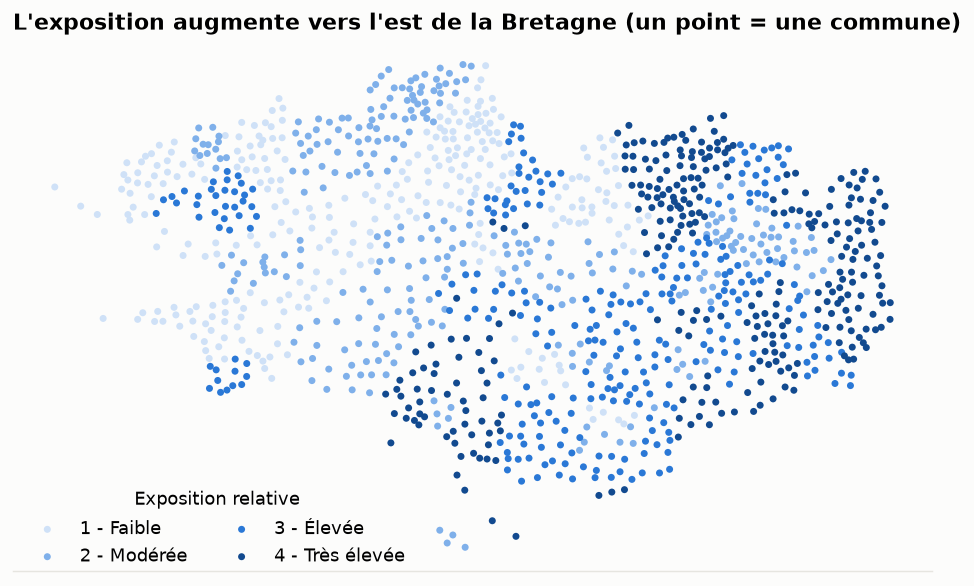

,communes,habitants
classe_exposition,,
1 - Faible,301,619439
2 - Modérée,300,595233
3 - Élevée,300,1075246
4 - Très élevée,301,1159452


In [8]:
classes = sorted(communes.classe_exposition.unique())
couleurs = dict(zip(classes, ["#cfe1f7", "#7fb0ea", "#2a78d6", "#124a8f"]))
fig, ax = plt.subplots(figsize=(8, 4.6))
for classe in classes:
    groupe = communes[communes.classe_exposition == classe]
    ax.scatter(groupe.longitude, groupe.latitude, s=15, color=couleurs[classe], label=classe, edgecolor="none")
ax.set_aspect(1.5); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
ax.legend(frameon=False, title="Exposition relative", loc="lower left", bbox_to_anchor=(0, -0.02), ncol=2)
ax.set_title("L'exposition augmente vers l'est de la Bretagne (un point = une commune)")
enregistrer("5_carte_exposition")
communes.groupby("classe_exposition").agg(communes=("population", "size"), habitants=("population", "sum"))

### Robustesse

Changer fortement les poids conserve l'ordre général (corrélation de 0,86 à 0,93), mais 19 à
30 % des communes du quartile le plus exposé changent selon le scénario. L'indice est donc fiable
pour repérer de grandes zones, pas pour départager deux communes voisines.

Deux biais sont à connaître. 78 % des écarts de gravité s'expliquent par le département : les
arrêtés reflètent aussi des pratiques préfectorales, pas seulement l'hydrologie. Et la pression
et la dépendance aux eaux de surface sont corrélées (0,69), ce qui compte en partie deux fois le
même phénomène.

In [9]:
composantes = communes.rename(columns={"score_gravite_annuel": "gravite", "pression_m3_km2": "pression", "part_eau_surface": "surface"})[["gravite", "pression", "surface"]]
reference = t.indice_exposition(composantes)
quartile = set(reference.nlargest(300).index)
scenarios = {
    "Poids égaux": dict(gravite=1/3, pression=1/3, surface=1/3),
    "Gravité dominante": dict(gravite=.7, pression=.2, surface=.1),
    "Pression dominante": dict(gravite=.3, pression=.5, surface=.2),
    "Eaux de surface renforcées": dict(gravite=.4, pression=.2, surface=.4),
}
lignes = []
for nom, poids in scenarios.items():
    variante = t.indice_exposition(composantes, poids)
    lignes.append({"scénario": nom, "rho de Spearman": round(variante.corr(reference, method="spearman"), 2),
                   "quartile haut conservé (%)": round(len(quartile & set(variante.nlargest(300).index)) / 3)})
pd.DataFrame(lignes).set_index("scénario")

,rho de Spearman,quartile haut conservé (%)
scénario,,
Poids égaux,0.89,77
Gravité dominante,0.89,70
Pression dominante,0.86,80
Eaux de surface renforcées,0.93,81


## 7. Ce qu'il faut retenir

1. **La vulnérabilité est structurelle.** Près de trois quarts de l'eau prélevée vient des eaux
   de surface, qui réagissent vite au manque de pluie.
2. **Deux crises majeures en cinq ans.** 2022 et 2026 concentrent l'essentiel des jours de crise
   de la série. Une période aussi courte ne suffit pas à établir une tendance climatique.
3. **Une PME est exposée même sans prélever.** Peu de PME prélèvent directement, mais leur
   territoire peut subir des restrictions. Le risque se lit donc au niveau de la commune.
4. **L'est de la région ressort le plus exposé**, notamment en Ille-et-Vilaine, avec une réserve
   sur le rôle des pratiques préfectorales.
5. **Le total de 2022 était trompeur.** À périmètre constant, les prélèvements économiques
   baissent, ce que le chiffre brut masquait.

**Prochaine étape pour une PME :** consulter la fiche de sa commune dans le tableau de bord, puis
estimer sa propre dépendance à l'eau, que seules ses factures permettent de mesurer.